# Bank-Route — Machine Learning Project
## AI-Driven Classification and Priority-Based Routing of Banking Customer Complaints
**Dataset:** US Consumer Finance Complaints (CFPB)  
**Dataset Source:** Kaggle  https://www.kaggle.com/datasets/kaggle/us-consumer-finance-complaints




## Project Summary (in simple words)

**Problem:** Banks receive thousands of complaints. Staff read each one manually, decide its type and urgency, and forward it to a department. This is slow and different employees decide differently.

**Our solution:** A supervised ML pipeline that reads the complaint text and predicts:
1. **Category** — which financial product the complaint is about
2. **Priority** — High / Medium / Low
3. **Department** — where it should be routed

```
Complaint text  -->  TF-IDF  -->  ML models  -->  Category + Priority  -->  Department
```

> The model only **suggests** to staff. The final decision stays with a human.

---
## Setup

Import the libraries we need.

In [1]:
import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
pd.set_option("display.max_colwidth", 120)

---
## 1. Problem Definition & Dataset Understanding

**What is this dataset?**  
The CFPB (Consumer Financial Protection Bureau, USA) collects complaints that customers file against financial companies. Each row is **one real complaint**.

**Who is a "consumer"?** An ordinary customer of a financial company, banks, credit card companies, mortgage/loan servicers, debt collectors.

**Important columns for us**

| Column | Meaning | Role in project |
|---|---|---|
| `consumer_complaint_narrative` | The complaint text written by the customer | **Input (X)** |
| `product` | Financial product category | **Target 1 — Category** |
| `issue` | Type of problem (e.g. Fraud, Billing dispute) | Used to build **Target 2 — Priority** |

**Tasks**
1. Load the CSV and check its shape and columns.
2. Check how many rows actually contain complaint text.

In [2]:
# Task 1 — load the dataset (works on Kaggle and on a local machine)
candidates = [
    "/kaggle/input/us-consumer-finance-complaints/consumer_complaints.csv",
    "/kaggle/input/datasets/kaggle/us-consumer-finance-complaints/consumer_complaints.csv",
    "consumer_complaints.csv",
]
DATA_PATH = next((p for p in candidates if os.path.exists(p)), None)
assert DATA_PATH is not None, "consumer_complaints.csv not found - add the dataset to the notebook"

df = pd.read_csv(DATA_PATH, low_memory=False)
print("Loaded from:", DATA_PATH)
print("Shape:", df.shape)
print(df.columns.tolist())

Loaded from: /kaggle/input/datasets/kaggle/us-consumer-finance-complaints/consumer_complaints.csv
Shape: (555957, 18)
['date_received', 'product', 'sub_product', 'issue', 'sub_issue', 'consumer_complaint_narrative', 'company_public_response', 'company', 'state', 'zipcode', 'tags', 'consumer_consent_provided', 'submitted_via', 'date_sent_to_company', 'company_response_to_consumer', 'timely_response', 'consumer_disputed?', 'complaint_id']


In [3]:
# Task 2 — how many rows have complaint text?
n_total = len(df)
n_text = df["consumer_complaint_narrative"].notna().sum()
print(f"Total rows            : {n_total:,}")
print(f"Rows with narrative   : {n_text:,}  ({n_text / n_total:.1%})")
df[["product", "issue", "consumer_complaint_narrative"]].dropna().sample(5, random_state=1)

Total rows            : 555,957
Rows with narrative   : 66,806  (12.0%)


,product,issue,consumer_complaint_narrative
258022,Debt collection,Communication tactics,"On first contact from P & B Capitol Group, LLC, a woman, who did not identify herself, yelled at me and was very abu..."
498755,Debt collection,Improper contact or sharing of info,I am writing regarding this agencies illegal collection practices. UCB is practicing completely illegal collection p...
306486,Debt collection,Cont'd attempts collect debt not owed,i got a call from a collection company regarding a unpaid bill from XXXX XXXX XXXX back from 2014. I did n't receive...
261329,Student loan,Getting a loan,We have a company sending a demand notice she said it is not a school loan we filed a chapter XXXX bankruptcy on XX/...
495265,Mortgage,"Loan modification,collection,foreclosure","My name is XXXX XXXX. Our family lives in XXXX, MI. and has lived in this house for the last 12 years and I am terri..."


**Observation 1:**  
The dataset contains **555,957** complaints, but only **66,806 (12.0%)** of them include the consumer complaint narrative (the text written by the customer). The remaining 88% have no text.

Our model learns by reading complaint text, so rows without a narrative cannot be used. Complaint text is the only input (X) for TF-IDF and the classifiers, so we keep only the rows that contain it. Even after this filtering we still have enough data for our planned sample of about 15,000 to 20,000 complaints.

---
## 2. Data Cleaning & Exploration

A text model can only learn from rows that contain text, so we keep only those.

*Concepts/functions:* `dropna()`, `value_counts()`, `str.len()`

**Tasks**
3. Keep rows that have `consumer_complaint_narrative`, `product` and `issue`.
4. Plot the number of complaints per product. Is the data balanced?
5. Check complaint length (number of words).

In [4]:
# Task 3 — keep only usable rows
data = df[["product", "issue", "consumer_complaint_narrative"]].dropna().copy()
data = data.rename(columns={"consumer_complaint_narrative": "text"})
data = data.drop_duplicates(subset="text").reset_index(drop=True)
print("Usable rows:", data.shape[0])
data["product"].value_counts()

Usable rows: 65646


product
Debt collection            17131
Mortgage                   14909
Credit reporting           11864
Credit card                 7908
Bank account or service     5688
Consumer Loan               3667
Student loan                2121
Prepaid card                 858
Payday loan                  726
Money transfers              665
Other financial service      109
Name: count, dtype: int64

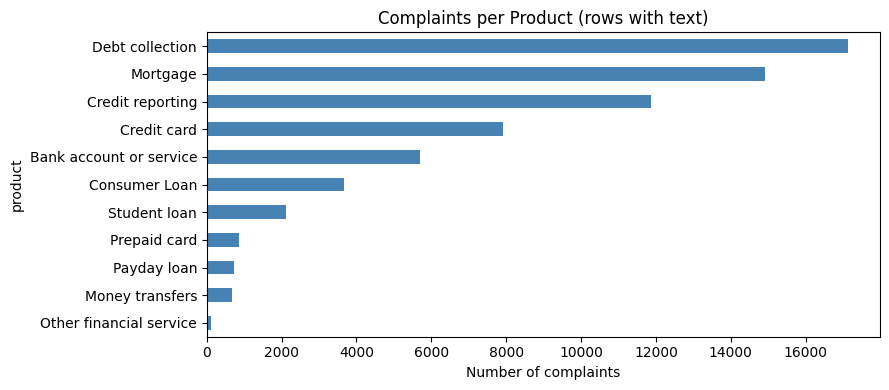

In [5]:
# Task 4 — class distribution
counts = data["product"].value_counts()
plt.figure(figsize=(9, 4))
counts.sort_values().plot(kind="barh", color="steelblue")
plt.title("Complaints per Product (rows with text)")
plt.xlabel("Number of complaints")
plt.tight_layout()
plt.show()

count    65646.0
mean       192.3
std        167.5
min          1.0
25%         72.0
50%        137.0
75%        257.0
max       1284.0
Name: n_words, dtype: float64


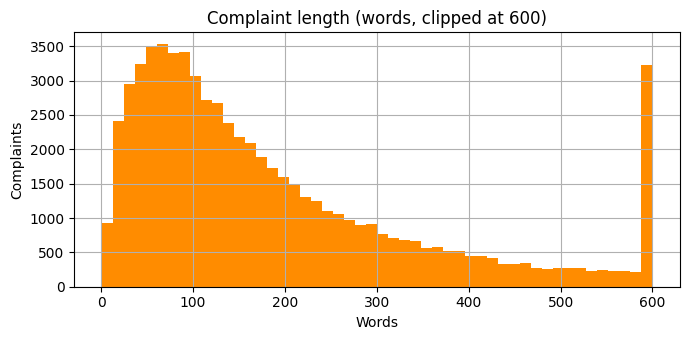

In [6]:
# Task 5 — complaint length
data["n_words"] = data["text"].str.split().str.len()
print(data["n_words"].describe().round(1))
plt.figure(figsize=(7, 3.5))
data["n_words"].clip(upper=600).hist(bins=50, color="darkorange")
plt.title("Complaint length (words, clipped at 600)")
plt.xlabel("Words"); plt.ylabel("Complaints")
plt.tight_layout(); plt.show()

**Observation 2:**  
After removing 1,160 duplicate complaints, 65,646 usable rows remain. The bar chart shows that the data is highly imbalanced. Debt collection (17,131), Mortgage (14,909) and Credit reporting (11,864) dominate the dataset, while Prepaid card, Payday loan, Money transfers and Other financial service are very small, with fewer than 900 complaints each. A model trained on such data tends to favour the large classes and ignore the small ones, so we balance the data in the next section.

Complaint length is right-skewed: the median is 137 words and the mean is 192, with a maximum of 1,284 words. The spike at 600 in the histogram appears because longer complaints were clipped at 600 for plotting. Since most complaints are short to medium in length, TF-IDF can represent them without any special handling.

---
## 3. Selecting Categories & Balancing the Data

Proposal scope: **bank-related** products. We exclude `Credit reporting` (it is about credit bureaus, not banks) and `Other financial service` (too few rows). We also drop any category with too few rows, and cap the big classes so the model does not simply learn the largest class.

**Tasks**
6. Choose the target categories.
7. Build a balanced sample (cap per class).

In [7]:
# Task 6 & 7 — choose categories and balance
EXCLUDE = ["Credit reporting", "Other financial service"]
MIN_ROWS = 500           # a category needs at least this many rows to be kept
MAX_PER_CLASS = 2500     # cap per category (total sample ~ 15,000 - 20,000)

counts = data["product"].value_counts()
keep = [c for c in counts.index if c not in EXCLUDE and counts[c] >= MIN_ROWS]
print("Categories kept:", keep)

parts = []
for c in keep:
    g = data[data["product"] == c]
    parts.append(g.sample(min(len(g), MAX_PER_CLASS), random_state=RANDOM_STATE))
sample = pd.concat(parts).sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

print("\nSample size:", len(sample))
sample["product"].value_counts()

Categories kept: ['Debt collection', 'Mortgage', 'Credit card', 'Bank account or service', 'Consumer Loan', 'Student loan', 'Prepaid card', 'Payday loan', 'Money transfers']

Sample size: 16870


product
Mortgage                   2500
Bank account or service    2500
Debt collection            2500
Credit card                2500
Consumer Loan              2500
Student loan               2121
Prepaid card                858
Payday loan                 726
Money transfers             665
Name: count, dtype: int64

**Observation 3:**  
We excluded "Credit reporting" (it concerns credit bureaus rather than banks) and "Other financial service" (only 109 complaints). The remaining 9 categories were kept: Debt collection, Mortgage, Credit card, Bank account or service, Consumer Loan, Student loan, Prepaid card, Payday loan and Money transfers.

Each category was capped at 2,500 complaints, giving a final sample of 16,870 complaints, which is within our planned range of 15,000 to 20,000. Balancing helps because a model trained on dominant classes tends to over-predict them; capping the large classes gives the smaller categories a fairer chance of being learned. The classes are still not perfectly equal (665 to 2,500), so we also use class weights during training.

---
## 4. Building the Priority Label (Rubric)

**Important:** the CFPB dataset has **no** High/Medium/Low column. We must create it ourselves, and we must say this clearly in the report.

**Idea:** priority depends on how serious the *issue* is, not on the product. We define a transparent, rule-based rubric using the `issue` column:

| Priority | Meaning | Example issues |
|---|---|---|
| **High** | Money/legal/identity risk, needs fast action | fraud, unauthorized transactions, identity theft, illegal threats, foreclosure |
| **Medium** | Financial problem, but not an emergency | billing disputes, fees, payments, account closing, loan servicing |
| **Low** | Information, communication or general issues | everything else |

**Why this is not cheating:** the model never sees the `issue` column. It only sees the complaint **text**, so it has to learn urgency from the words the customer wrote.

**Tasks**
8. Implement the rubric.
9. Check the priority distribution and review the issue-to-priority mapping.

In [8]:
# Task 8 — priority rubric (rule-based, transparent)
HIGH_KW = ["fraud", "unauthorized", "identity theft", "embezzlement", "scam", "stolen",
           "illegal", "threat", "not owed", "foreclosure"]
MEDIUM_KW = ["billing", "fee", "deposit", "withdrawal", "payment", "charge", "dispute",
             "closing", "unable to pay", "can't repay", "struggling", "funds being low",
             "transaction", "servicing", "modification", "collection", "false statement", "interest","atm"]

def assign_priority(issue):
    s = str(issue).lower()
    if any(k in s for k in HIGH_KW):
        return "High"
    if any(k in s for k in MEDIUM_KW):
        return "Medium"
    return "Low"

sample["priority"] = sample["issue"].apply(assign_priority)
print(sample["priority"].value_counts())

priority
Medium    7272
Low       6528
High      3070
Name: count, dtype: int64


In [9]:
# Task 9 — review the mapping (check that it makes sense!)
mapping = (sample.groupby(["priority", "issue"]).size()
                 .reset_index(name="count")
                 .sort_values(["priority", "count"], ascending=[True, False]))
mapping.groupby("priority").head(8)

,priority,issue,count
0,High,Cont'd attempts collect debt not owed,1031
3,High,"Loan modification,collection,foreclosure",868
1,High,Fraud or scam,424
5,High,Unauthorized transactions/trans. issues,296
2,High,Identity theft / Fraud / Embezzlement,239
4,High,Taking/threatening an illegal action,212
25,Low,Dealing with my lender or servicer,1354
35,Low,Managing the loan or lease,1143
27,Low,Disclosure verification of debt,414
48,Low,Taking out the loan or lease,410


**Observation 4:**  
The dataset has no priority label, so we created one using a transparent rule-based rubric on the "issue" column. Issues containing keywords such as fraud, unauthorized, stolen or foreclosure were labelled High; issues about fees, billing, payments, ATM problems or disputes were labelled Medium; all remaining issues were labelled Low.

The resulting distribution is Medium (7,272; 43%), Low (6,528; 39%) and High (3,070; 18%). All three classes are well represented, and High is the smallest, which is realistic because urgent complaints are less frequent. After reviewing the mapping, we added the keyword "atm" to the Medium list, because complaints about debit or ATM cards often involve blocked or wrongly debited money and were initially labelled Low.

We agree with the rubric for "Fraud or scam", "Unauthorized transactions" and "Cont'd attempts collect debt not owed", which are correctly marked High, and for "Billing disputes", which is correctly Medium. "Problems when you are unable to pay" could also be argued as High because of the risk of foreclosure. These labels are a proxy designed by us rather than ground truth from real bank staff, which is a limitation of this project.

---
## 5. Text Preprocessing & TF-IDF

**Cleaning:** the CFPB hides personal data as `XXXX` and `{$123.00}`. We remove these, lowercase the text, and keep only letters.

**TF-IDF:** converts text into numbers. A word gets a high score if it is frequent in *this* complaint but rare across *all* complaints (e.g. "unauthorized" is informative, "the" is not).

**Tasks**
10. Clean the text.
11. Split into train/test **first**, then fit TF-IDF on the training text only (to avoid data leakage).

In [10]:
# Task 10 — clean text
def clean_text(t):
    t = str(t).lower()
    t = re.sub(r"x{2,}", " ", t)          # masked data like XXXX
    t = re.sub(r"\{\$?[\d.,]+\}", " ", t)   # masked money like {$12.00}
    t = re.sub(r"[^a-z\s]", " ", t)       # keep letters only
    t = re.sub(r"\s+", " ", t).strip()
    return t

sample["clean"] = sample["text"].apply(clean_text)
sample[["text", "clean"]].head(10)

,text,clean
0,This complaint is in reference to release of insurance money owed to us by Green Tree Mortgage for flood damage that...,this complaint is in reference to release of insurance money owed to us by green tree mortgage for flood damage that...
1,I took out Sallie Mae loans each of the three years that I attended XXXX XXXX University XXXX ( near XXXX XXXX. Shor...,i took out sallie mae loans each of the three years that i attended university near shortly before graduating i deve...
2,"I received a prepaid debit card ( XXXX ) for a rebate. Its exp date was XXXX. I misplaced the card around XXXX, and ...",i received a prepaid debit card for a rebate its exp date was i misplaced the card around and just found it i called...
3,I received a loan for XXXX from mypaydayloan.com. I needed to change my banking info but I 've been unable to log in...,i received a loan for from mypaydayloan com i needed to change my banking info but i ve been unable to log in to see...
4,I opened a business account with BB & T XX/XX/XXXX I did not realize until it was time for me to turn my bank statem...,i opened a business account with bb t i did not realize until it was time for me to turn my bank statements over to ...
5,On XX/XX/XXXX I bought a prepaid debit card through NetSpend from my local grocery store ( XXXX ). I purchased the c...,on i bought a prepaid debit card through netspend from my local grocery store i purchased the card for and put on th...
6,"I had made my car payment on XXXX XXXX, 2015 in cash by visiting the Bank of America branch. \nI got a phone call ap...",i had made my car payment on in cash by visiting the bank of america branch i got a phone call approximately one wee...
7,XX/XX/2015 according to First Investors Servicing Corporation I had satisfied the principle lender and paid all the ...,according to first investors servicing corporation i had satisfied the principle lender and paid all the concurrent ...
8,"On XXXX XXXX, I made an automatic e-pay of {$4800.00} to my Banana Republic Credit Card ( Through Synchrony Bank XXX...",on i made an automatic e pay of to my banana republic credit card through synchrony bank account from my checking ac...
9,Used XXXX to load money on my prepaid PayPower XXXX card but it was not added to my account. Have a confirmation rec...,used to load money on my prepaid paypower card but it was not added to my account have a confirmation receipt from h...


**Observation:**  
Complaint text was converted to lowercase, and the masked placeholders used by the CFPB (such as "XXXX" and masked amounts like "{$12.00}") were removed, since they carry no meaning for classification. Numbers and punctuation were also removed so that only letters remain, and extra spaces were collapsed. The cleaned text keeps the key words of each complaint while reducing noise, which helps TF-IDF focus on informative terms.

In [11]:
# Task 11 — train/test split (stratified on category), then TF-IDF
X_train_txt, X_test_txt, yc_train, yc_test, yp_train, yp_test = train_test_split(
    sample["clean"], sample["product"], sample["priority"],
    test_size=0.2, random_state=RANDOM_STATE, stratify=sample["product"])

tfidf = TfidfVectorizer(stop_words="english", ngram_range=(1, 2),
                        min_df=5, max_features=20000, sublinear_tf=True)
X_train = tfidf.fit_transform(X_train_txt)   # fit on TRAIN only
X_test = tfidf.transform(X_test_txt)         # only transform on TEST

print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (13496, 20000) | Test: (3374, 20000)


**Observation:**  
The sample of 16,870 complaints was split into 13,496 training (80%) and 3,374 test (20%) rows. The split is stratified on product category so that small classes such as Money transfers appear in both sets in the same proportion. The TF-IDF vectorizer uses unigrams and bigrams, removes English stop words and keeps the top 20,000 features. It was fitted on the training data only and then applied to the test data, which prevents data leakage and keeps the evaluation honest.

---
## 6. Model 1 — Complaint Category Classification

We compare the four planned models: **Multinomial Naive Bayes, Logistic Regression, SVM (LinearSVC), Random Forest**.

Because categories are many (multi-class), we report **weighted** precision / recall / F1, plus accuracy.

**Tasks**
12. Train all four models for category prediction and build a comparison table.
13. Which model is best, and why?

In [12]:
# helper: train + evaluate several models
def run_models(models, Xtr, ytr, Xte, yte):
    rows, fitted, preds = [], {}, {}
    for name, m in models.items():
        m.fit(Xtr, ytr)
        p = m.predict(Xte)
        fitted[name], preds[name] = m, p
        rows.append({
            "Model": name,
            "Accuracy": accuracy_score(yte, p),
            "Precision": precision_score(yte, p, average="weighted", zero_division=0),
            "Recall": recall_score(yte, p, average="weighted", zero_division=0),
            "F1-score": f1_score(yte, p, average="weighted", zero_division=0),
        })
    table = pd.DataFrame(rows).set_index("Model").round(4)
    return table, fitted, preds

def make_models():
    return {
        "Naive Bayes": MultinomialNB(),
        "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
        "SVM (LinearSVC)": LinearSVC(class_weight="balanced"),
        "Random Forest": RandomForestClassifier(n_estimators=150, n_jobs=-1,
                                                class_weight="balanced", random_state=RANDOM_STATE),
    }

In [13]:
# Task 12 — category models
cat_table, cat_models, cat_preds = run_models(make_models(), X_train, yc_train, X_test, yc_test)
cat_table.sort_values("F1-score", ascending=False)

,Accuracy,Precision,Recall,F1-score
Model,,,,
SVM (LinearSVC),0.8388,0.8404,0.8388,0.8386
Logistic Regression,0.8370,0.8400,0.8370,0.8375
Random Forest,0.8079,0.8131,0.8079,0.8064
Naive Bayes,0.7543,0.7901,0.7543,0.7241


**Observation 6:**  
SVM (LinearSVC) achieved the best weighted F1-score (0.8386) with an accuracy of 0.8388, followed very closely by Logistic Regression (F1 = 0.8375). Random Forest reached 0.8064 and Naive Bayes was the weakest with 0.7241. The two linear models perform best because TF-IDF produces high-dimensional, sparse vectors, which linear classifiers handle well. Naive Bayes serves as a fast baseline: its F1-score is noticeably lower than its accuracy, suggesting it struggles with the smaller categories.

Best category model: SVM (LinearSVC)


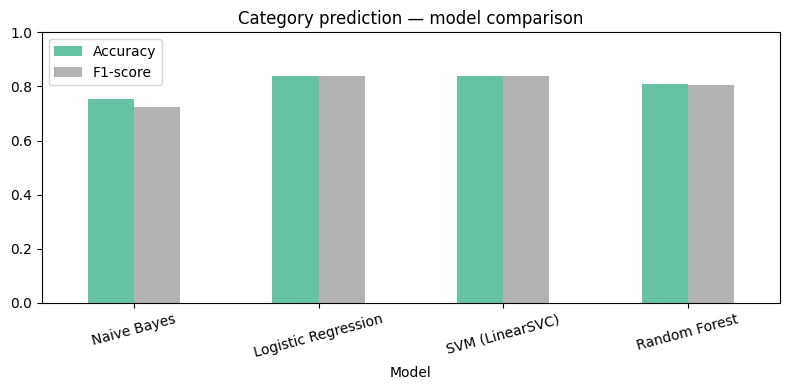

In [14]:
# Task 13 — best model + visual comparison
best_cat_name = cat_table["F1-score"].idxmax()
print("Best category model:", best_cat_name)

cat_table[["Accuracy", "F1-score"]].plot(kind="bar", figsize=(8, 4), rot=15, colormap="Set2")
plt.ylim(0, 1); plt.title("Category prediction — model comparison")
plt.tight_layout(); plt.show()

                         precision    recall  f1-score   support

Bank account or service       0.82      0.80      0.81       500
          Consumer Loan       0.82      0.75      0.79       500
            Credit card       0.78      0.86      0.81       500
        Debt collection       0.79      0.84      0.81       500
        Money transfers       0.84      0.82      0.83       133
               Mortgage       0.91      0.94      0.93       500
            Payday loan       0.73      0.66      0.69       145
           Prepaid card       0.86      0.88      0.87       172
           Student loan       0.96      0.89      0.93       424

               accuracy                           0.84      3374
              macro avg       0.84      0.83      0.83      3374
           weighted avg       0.84      0.84      0.84      3374



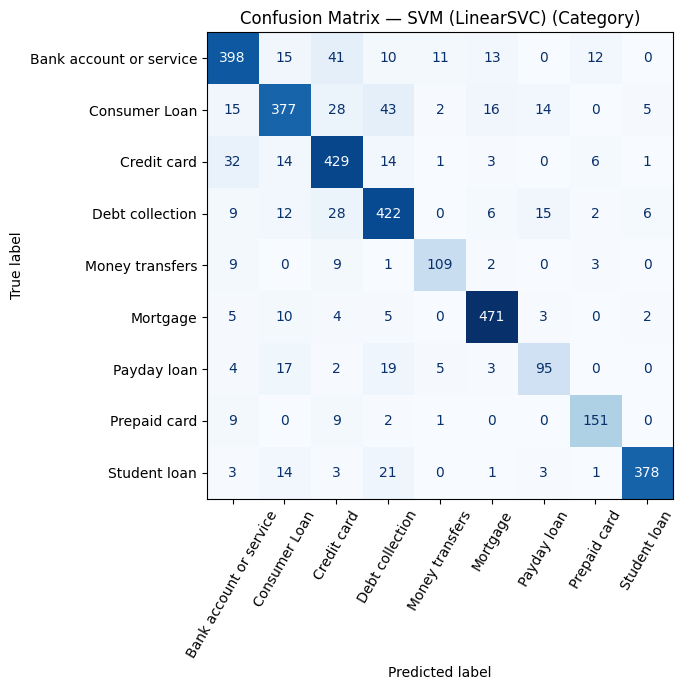

In [15]:
# Detailed report + confusion matrix of the best model
best_cat_pred = cat_preds[best_cat_name]
print(classification_report(yc_test, best_cat_pred, zero_division=0))

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(yc_test, best_cat_pred, xticks_rotation=60,
                                        cmap="Blues", ax=ax, colorbar=False)
ax.set_title(f"Confusion Matrix — {best_cat_name} (Category)")
plt.tight_layout(); plt.show()

**Observation:**  
The SVM reaches an overall accuracy of 0.84 on the 3,374 test complaints (macro F1 0.83). Mortgage and Student loan are predicted best (F1 = 0.93), followed by Prepaid card (0.87). Payday loan is the weakest category (F1 = 0.69, recall = 0.66). The confusion matrix shows that the most frequent errors occur between topically similar categories: Payday loan is often confused with Debt collection (19) and Consumer Loan (17), Consumer Loan with Debt collection (43) and Credit card (28), Bank account with Credit card (41), and Student loan with Debt collection (21). These categories share vocabulary such as payments, fees and collection, which makes them hard to separate using text alone. Small classes such as Money transfers and Prepaid card are still predicted well, which suggests that balancing and class weights were effective.

---
## 7. Model 2 — Priority Prediction

Same four models, now predicting **High / Medium / Low** from the complaint text.

**Why recall of "High" matters most:** a missed urgent complaint (for example an unauthorized transaction) is much worse than a normal complaint wrongly marked urgent. So besides overall F1 we also look at the **recall of the High class**.

**Tasks**
14. Train all four models for priority prediction.
15. Compare them using overall F1 **and** recall of High.

In [16]:
# Task 14 — priority models
pri_table, pri_models, pri_preds = run_models(make_models(), X_train, yp_train, X_test, yp_test)

# Task 15 — add recall of the High class
pri_table["High Recall"] = [
    recall_score(yp_test, pri_preds[n], labels=["High"], average="macro", zero_division=0)
    for n in pri_table.index]
pri_table.round(4).sort_values("F1-score", ascending=False)

,Accuracy,Precision,Recall,F1-score,High Recall
Model,,,,,
Logistic Regression,0.6621,0.6727,0.6621,0.6639,0.7174
Random Forest,0.6517,0.6522,0.6517,0.6462,0.4112
SVM (LinearSVC),0.6381,0.6394,0.6381,0.6386,0.5668
Naive Bayes,0.6218,0.6440,0.6218,0.5927,0.1506


Best priority model (by F1): Logistic Regression
Highest recall for High class: Logistic Regression
              precision    recall  f1-score   support

        High       0.54      0.72      0.62       591
      Medium       0.73      0.64      0.68      1446
         Low       0.67      0.66      0.67      1337

    accuracy                           0.66      3374
   macro avg       0.65      0.67      0.65      3374
weighted avg       0.67      0.66      0.66      3374



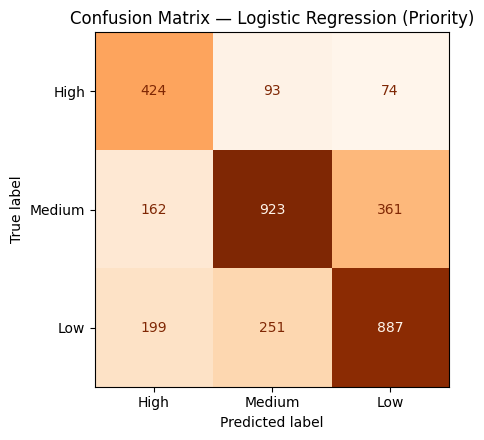

In [17]:
best_pri_name = pri_table["F1-score"].idxmax()
print("Best priority model (by F1):", best_pri_name)
print("Highest recall for High class:", pri_table["High Recall"].idxmax())

best_pri_pred = pri_preds[best_pri_name]
print(classification_report(yp_test, best_pri_pred, labels=["High", "Medium", "Low"], zero_division=0))

fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_predictions(yp_test, best_pri_pred, labels=["High", "Medium", "Low"],
                                        cmap="Oranges", ax=ax, colorbar=False)
ax.set_title(f"Confusion Matrix — {best_pri_name} (Priority)")
plt.tight_layout(); plt.show()

**Observation 7:**  
_(Write: best model for priority, its High recall, and how many High complaints were pushed to Medium/Low. Is that acceptable for a bank?)_

---
## 8. Department Routing

The model predicts the **category**; the department comes from a **mapping table** that we define as an assumption (real banks have their own structure).

**Tasks**
16. Define the category-to-department mapping.
17. Build `triage()` that takes raw complaint text and returns category, priority and department.
18. Test it on example complaints.

In [18]:
# Task 16 — mapping table (our assumption, document it in the report)
DEPARTMENTS = {
    "Bank account or service": "Accounts & Deposits Team",
    "Credit card":             "Card Services Team",
    "Consumer Loan":           "Retail Lending Team",
    "Mortgage":                "Mortgage & Home Loans Team",
    "Student loan":            "Education Loans Team",
    "Debt collection":         "Recovery & Collections Team",
    "Payday loan":             "Retail Lending Team",
    "Money transfers":         "Payments & Remittances Team",
    "Prepaid card":            "Card Services Team",
}
pd.DataFrame(list(DEPARTMENTS.items()), columns=["Category", "Department"])

,Category,Department
0,Bank account or service,Accounts & Deposits Team
1,Credit card,Card Services Team
2,Consumer Loan,Retail Lending Team
3,Mortgage,Mortgage & Home Loans Team
4,Student loan,Education Loans Team
5,Debt collection,Recovery & Collections Team
6,Payday loan,Retail Lending Team
7,Money transfers,Payments & Remittances Team
8,Prepaid card,Card Services Team


In [19]:
# Task 17 — final triage function
final_cat_model = cat_models[best_cat_name]
final_pri_model = pri_models[best_pri_name]

def triage(complaint_text):
    vec = tfidf.transform([clean_text(complaint_text)])
    category = final_cat_model.predict(vec)[0]
    priority = final_pri_model.predict(vec)[0]
    department = DEPARTMENTS.get(category, "General Support")
    return {"category": category, "priority": priority, "department": department}

# Task 18 — try it
examples = [
    "Someone made unauthorized transactions on my account and I did not approve them. I need help urgently.",
    "My credit card statement shows a late fee even though I paid on time.",
    "The debt collector keeps calling me about a debt that I do not owe and threatens legal action.",
    "I want to know how to change my mailing address on my mortgage account.",
]
pd.DataFrame([{"complaint": e[:70] + "...", **triage(e)} for e in examples])

,complaint,category,priority,department
0,Someone made unauthorized transactions on my account and I did not app...,Bank account or service,Medium,Accounts & Deposits Team
1,My credit card statement shows a late fee even though I paid on time....,Credit card,Medium,Card Services Team
2,The debt collector keeps calling me about a debt that I do not owe and...,Debt collection,High,Recovery & Collections Team
3,I want to know how to change my mailing address on my mortgage account...,Mortgage,High,Mortgage & Home Loans Team


**Observation 8:**  
_(Write: did the predictions look sensible? Which example surprised you?)_

---
## 9. Error Analysis

Metrics hide *why* a model fails. Let us read a few wrongly classified complaints.

**Task**
19. Show misclassified test complaints (category) and explain the reasons.

In [20]:
# Task 19 — look at mistakes
errors = pd.DataFrame({
    "text": X_test_txt.values,
    "true": yc_test.values,
    "predicted": best_cat_pred,
})
errors = errors[errors["true"] != errors["predicted"]]
print(f"Misclassified: {len(errors)} of {len(yc_test)} ({len(errors) / len(yc_test):.1%})")
errors.sample(min(5, len(errors)), random_state=3)

Misclassified: 544 of 3374 (16.1%)


,text,true,predicted
75,i found out i have a judgement on my record after looking into it and verifying this was mine i contacted chase and ...,Credit card,Debt collection
153,i m still in school getting ready to do ca n t find a job anywhere i m getting harassing phone calls i have told the...,Student loan,Consumer Loan
2050,ref car ref this is the times bank of america refused to give me credit i had been trying to reestablished an accoun...,Consumer Loan,Bank account or service
237,my name is and my employer posted our direct deposit on friday in which with rushcard i usually get my deposit on mo...,Bank account or service,Prepaid card
2616,riamoneytransfer was contracted to provide payment service after taking money they blocked account payment was not m...,Money transfers,Bank account or service


**Observation 9:**  
_(Write 2-3 reasons: for example complaints that mention two products, very short text, or categories with similar vocabulary such as Consumer Loan vs Student loan.)_

---
## 10. Save the Model & Streamlit App

We save the trained objects so the Streamlit web app can load them.

**Tasks**
20. Save TF-IDF + both models with `joblib`.
21. Create `app.py` (Streamlit GUI).

---
## 11. Final Summary Table

In [21]:
summary = pd.DataFrame({
    "Task": ["Category", "Priority"],
    "Best Model": [best_cat_name, best_pri_name],
    "Accuracy": [cat_table.loc[best_cat_name, "Accuracy"], pri_table.loc[best_pri_name, "Accuracy"]],
    "F1 (weighted)": [cat_table.loc[best_cat_name, "F1-score"], pri_table.loc[best_pri_name, "F1-score"]],
})
summary.round(4)

,Task,Best Model,Accuracy,F1 (weighted)
0,Category,SVM (LinearSVC),0.8388,0.8386
1,Priority,Logistic Regression,0.6621,0.6639


In [22]:
import joblib
from IPython.display import FileLink

# Sirf trained TF-IDF aur Category Model ko save karein
joblib.dump(tfidf, 'tfidf_vectorizer.pkl')
joblib.dump(cat_models[best_cat_name], 'category_model.pkl')

print("Files Successfully Saved! \n")

display(FileLink('tfidf_vectorizer.pkl'))
display(FileLink('category_model.pkl'))

Files Successfully Saved! 



/kaggle/working/tfidf_vectorizer.pkl

/kaggle/working/category_model.pkl

---
## 12. Conclusion, Limitations & Future Work

**Conclusion**  

**Limitations (be honest in the report)**
- Dataset is from the **US (CFPB)**, not Pakistani banks, so categories and wording differ from Pakistan's complaint system (SBP Sunwai).
- **Priority labels are rule-based proxies** built from the `issue` column, not labels from bank staff.
- The department mapping is an **assumption**.
- Complaints with several problems in one text are hard to classify with a single label.

**Future work**
- Use real labelled Pakistani complaints, including **Urdu / Roman Urdu** text.
- Replace TF-IDF with transformer embeddings.
- Measure actual time saved in triage with a pilot study.
- Add a human review step for low-confidence predictions.